In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [2]:
lagged_liheap = pd.read_csv("TimeLag_PolicyAnnotated.csv")
CalFresh = pd.read_csv("CalFresh_cleaned.csv")
FoodBank = pd.read_csv("FoodBank_cleaned.csv")

**Rename Month Year Column in CalFresh and Food Bank datasets**

In [3]:
CalFresh = CalFresh.rename(columns={"Month Year": "Month_Year"})
FoodBank = FoodBank.rename(columns={"Month Year": "Month_Year"})

**Merge CalFresh**

In [4]:
CalFresh_Merged = (
    CalFresh.groupby(["Zip Code", "Month_Year"], as_index=False)["Calfresh Dollars"].sum()
    .rename(columns={"Calfresh Dollars": "CalFresh_Total_Dollars"})
)

In [5]:
CalFresh_Merged

,Zip Code,Month_Year,CalFresh_Total_Dollars
0,91901,2020-01,101567.00
1,91901,2020-02,103182.00
2,91901,2020-03,111982.00
3,91901,2020-04,215626.00
4,91901,2020-05,225830.00
...,...,...,...
10868,92198,2025-04,7966.02
10869,92198,2025-05,9157.02
10870,92198,2025-06,10087.03
10871,92198,2025-07,9229.00


**Merge FoodBank**

In [6]:
FoodBank_Merged = (
    FoodBank.groupby(["Zip Code", "Month_Year"], as_index=False)["Pounds_Distributed"].sum()
    .rename(columns={"Pounds_Distributed": "FoodBank_Pounds_of_Food_Distributed"})
)

FoodBank_Merged

,Zip Code,Month_Year,FoodBank_Pounds_of_Food_Distributed
0,91901,2018-01,7884.000000
1,91901,2018-02,10558.000000
2,91901,2018-03,10642.000000
3,91901,2018-04,12192.000000
4,91901,2018-05,10370.000000
...,...,...,...
9379,92173,2025-04,136072.197909
9380,92173,2025-05,135546.664942
9381,92173,2025-06,134707.021539
9382,92173,2025-07,136228.789802


**Set records and zip code combination for food bank data were pounds of food donated = 0 to np.nan**

In [7]:
col = "FoodBank_Pounds_of_Food_Distributed"
print('Food bank zip-months recorded as 0:', (FoodBank_Merged[col] == 0).sum())
FoodBank_Merged.loc[FoodBank_Merged[col] == 0, col] = np.nan

Food bank zip-months recorded as 0: 1700


In [8]:
df = (lagged_liheap.merge(CalFresh_Merged, on=["Zip Code", "Month_Year"], how="left", validate="one_to_one")
     .merge(FoodBank_Merged, on=["Zip Code", "Month_Year"], how="left", validate="one_to_one"))

assert len(df) == len(lagged_liheap)
df = df.rename(columns={"Enrollment_Count": "LIHEAP_Enrollment_Count"})

In [9]:
df

,Zip Code,Month_Year,LIHEAP_Enrollment_Count,LIHEAP_lag1,LIHEAP_lag2,LIHEAP_lag3,lag1_status,lag2_status,lag3_status,Complete_Lags,...,LIHEAP_Policy_Change,FoodBank_Policy_Change,Any_Policy_Change,Policy_Period_EA_Ended,Policy_Period_ABWD_Resumed,Policy_Period_LIHEAP_FY24_Cut,LIHEAP_Direction_Increased,LIHEAP_Direction_Decreased,CalFresh_Total_Dollars,FoodBank_Pounds_of_Food_Distributed
0,91901,2023-03,2.0,1.0,NaN,NaN,present,zip_gap,before_start,False,...,0,0,0,0,0,0,1,0,355789.00,51489.0
1,91901,2023-04,1.0,2.0,1.0,NaN,present,present,zip_gap,False,...,0,1,1,1,0,0,1,0,230000.00,26145.0
2,91901,2023-05,2.0,1.0,2.0,1.0,present,present,present,True,...,0,0,0,1,0,0,1,0,230786.00,27788.0
3,91901,2023-06,2.0,2.0,1.0,2.0,present,present,present,True,...,0,0,0,1,0,0,1,0,219267.00,17225.0
4,91901,2023-07,1.0,2.0,2.0,1.0,present,present,present,True,...,0,1,1,1,1,0,1,0,207889.59,20383.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
847,92198,2023-03,NaN,NaN,1.0,NaN,zip_gap,present,before_start,False,...,0,0,0,0,0,0,1,0,10497.00,NaN
848,92198,2023-04,1.0,NaN,NaN,1.0,zip_gap,zip_gap,present,False,...,0,1,1,1,0,0,1,0,5568.00,NaN
849,92198,2023-05,NaN,1.0,NaN,NaN,present,zip_gap,zip_gap,False,...,0,0,0,1,0,0,1,0,5909.00,NaN
850,92198,2023-06,NaN,NaN,1.0,NaN,zip_gap,present,zip_gap,False,...,0,0,0,1,0,0,1,0,5939.00,NaN


**PErform a coverage check, how many rows have each outcome by month**

In [10]:
LAGS = [0, 1, 2, 3]

OUTCOMES = {"CalFresh_Total_Dollars": "CalFresh ($)", "FoodBank_Pounds_of_Food_Distributed": "Food bank (lbs)"}
display(df.groupby("Month_Year")[["LIHEAP_Enrollment_Count", "CalFresh_Total_Dollars", "FoodBank_Pounds_of_Food_Distributed"]].count())

,LIHEAP_Enrollment_Count,CalFresh_Total_Dollars,FoodBank_Pounds_of_Food_Distributed
Month_Year,,,
2023-02,64,78,66
2023-03,77,95,76
2023-04,84,102,79
2023-05,80,102,79
2023-06,74,104,77
2023-07,74,106,81
2023-08,0,98,79
2023-09,0,89,76
2023-10,0,76,68


**Define the Policy Stable Subset**

In [11]:
df["No_Policy_Change"] = (df["Any_Policy_Change"] == 0).astype(int)

print(df.groupby("Month_Year")[["Any_Policy_Change", "No_Policy_Change"]].first())
print('\Stable Months:', sorted(df.loc[df.No_Policy_Change == 1, "Month_Year"].unique()))

PERIODS = {
    "Full Period": df,
    "No_Policy_Change": df[df.No_Policy_Change == 1],
    "Policy_Change": df[df.Any_Policy_Change == 1],
}

            Any_Policy_Change  No_Policy_Change
Month_Year                                     
2023-02                     1                 0
2023-03                     0                 1
2023-04                     1                 0
2023-05                     0                 1
2023-06                     0                 1
2023-07                     1                 0
2023-08                     0                 1
2023-09                     1                 0
2023-10                     1                 0
\Stable Months: ['2023-03', '2023-05', '2023-06', '2023-08']


**Perform the Lagged Correlations**

In [12]:
LIHEAP_COLS = {0: "LIHEAP_Enrollment_Count", 1: "LIHEAP_lag1", 2: "LIHEAP_lag2", 3: "LIHEAP_lag3"}

In [13]:
def demean(d, cols):
    return d[cols] - d.groupby("Zip Code")[cols].transform("mean")

rows = []
for period, d in PERIODS.items():
    for out in OUTCOMES:
        for k in LAGS:
            x = LIHEAP_COLS[k]
            sub = d[["Zip Code", "Month_Year", x, out]].dropna()
            n = len(sub)
            if n < 10 or sub[x].nunique() < 2:
                rows.append(dict(Period=period, Outcome=out, Lag=k, n=n, months=sub.Month_Year.nunique()))
                continue
            pr, pp = stats.pearsonr(sub[x], sub[out])
            sr, sp = stats.spearmanr(sub[x], sub[out])

            sub2 = sub[sub.groupby("Zip Code")[x].transform("size") >= 2]
            dm = demean(sub2, [x, out])
            wr, wp = (
                stats.pearsonr(dm[x], dm[out]) if len(dm) >= 10 and dm[x].std() > 0 else (np.nan, np.nan)
            )

            rows.append(dict(Period=period, Outcome=out, Lag=k, n=n, months=sub.Month_Year.nunique(),
                            Pearson_r=pr, Pearson_p=pp, Spearman_rho=sr, Spearman_p=sp,
                            WithinZip_r=wr, WithinZip_p=wp, WithinZip_n=len(dm)))

res = pd.DataFrame(rows)
pd.set_option('display.float_format', '{:.3f}'.format)
res

,Period,Outcome,Lag,n,months,Pearson_r,Pearson_p,Spearman_rho,Spearman_p,WithinZip_r,WithinZip_p,WithinZip_n
0,Full Period,CalFresh_Total_Dollars,0,453,6,0.566,0.000,0.644,0.000,0.176,0.000,441
1,Full Period,CalFresh_Total_Dollars,1,577,7,0.567,0.000,0.681,0.000,-0.032,0.458,552
2,Full Period,CalFresh_Total_Dollars,2,578,7,0.549,0.000,0.679,0.000,-0.226,0.000,552
3,Full Period,CalFresh_Total_Dollars,3,577,7,0.594,0.000,0.696,0.000,-0.405,0.000,552
4,Full Period,FoodBank_Pounds_of_Food_Distributed,0,419,6,0.348,0.000,0.473,0.000,0.021,0.668,416
5,Full Period,FoodBank_Pounds_of_Food_Distributed,1,502,7,0.340,0.000,0.457,0.000,-0.032,0.480,498
6,Full Period,FoodBank_Pounds_of_Food_Distributed,2,504,7,0.333,0.000,0.459,0.000,-0.006,0.885,500
7,Full Period,FoodBank_Pounds_of_Food_Distributed,3,504,7,0.346,0.000,0.457,0.000,0.081,0.070,500
8,No_Policy_Change,CalFresh_Total_Dollars,0,231,3,0.557,0.000,0.657,0.000,0.154,0.022,222
9,No_Policy_Change,CalFresh_Total_Dollars,1,332,4,0.597,0.000,0.688,0.000,0.125,0.028,310


**Set up HeatMap for Correlations**

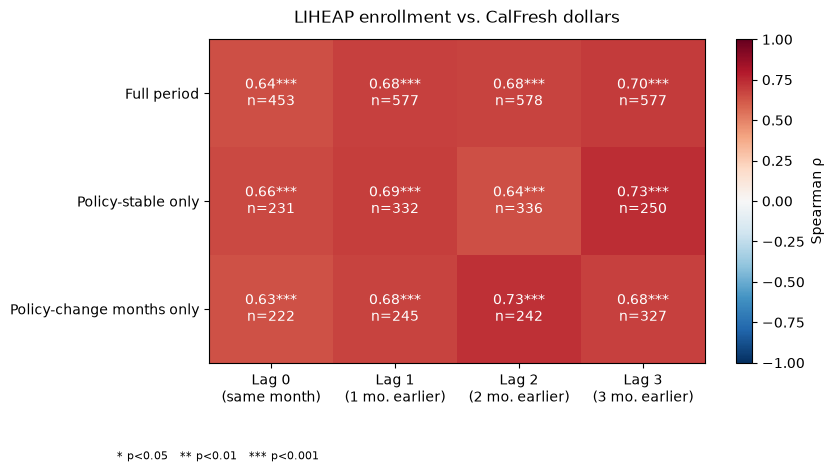

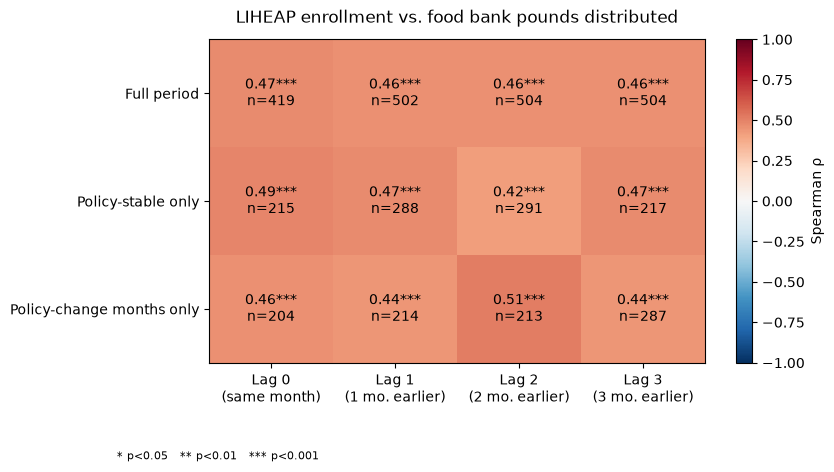

In [14]:
PERIOD_LABELS = {"Full Period": "Full period",
                 "No_Policy_Change": "Policy-stable only",
                 "Policy_Change": "Policy-change months only"}

def stars(p):
    return "***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else ""

def plot_lag_corr(outcome, title, filename):
    sub = res[res["Outcome"] == outcome]
    rho  = sub.pivot(index="Period", columns="Lag", values="Spearman_rho").reindex(index=list(PERIODS), columns=LAGS)
    pval = sub.pivot(index="Period", columns="Lag", values="Spearman_p").reindex(index=list(PERIODS), columns=LAGS)
    n    = sub.pivot(index="Period", columns="Lag", values="n").reindex(index=list(PERIODS), columns=LAGS)

    fig, ax = plt.subplots(figsize=(8, 4.2))
    im = ax.imshow(rho.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    for i in range(rho.shape[0]):
        for j in range(rho.shape[1]):
            r = rho.values[i, j]
            label = "—" if np.isnan(r) else f"{r:.2f}{stars(pval.values[i, j])}\nn={int(n.values[i, j])}"
            ax.text(j, i, label, ha="center", va="center", fontsize=10,
                    color="white" if abs(np.nan_to_num(r)) > 0.6 else "black")
    ax.set_xticks(range(len(LAGS)),
                  ["Lag 0\n(same month)" if k == 0 else f"Lag {k}\n({k} mo. earlier)" for k in LAGS])
    ax.set_yticks(range(len(PERIODS)), [PERIOD_LABELS.get(p, p) for p in PERIODS])
    ax.set_title(title, pad=12)
    fig.colorbar(im, ax=ax, label="Spearman ρ")
    fig.text(0.01, -0.12, "* p<0.05   ** p<0.01   *** p<0.001", fontsize=8)
    plt.savefig(filename, dpi=150, bbox_inches="tight")
    plt.show()


# Graphic 1: LIHEAP vs. CalFresh
plot_lag_corr("CalFresh_Total_Dollars",
              "LIHEAP enrollment vs. CalFresh dollars",
              "TimeLag_LIHEAP_CalFresh.png")

# Graphic 2: LIHEAP vs. food bank
plot_lag_corr("FoodBank_Pounds_of_Food_Distributed",
              "LIHEAP enrollment vs. food bank pounds distributed",
              "TimeLag_LIHEAP_FoodBank.png")

**Conclusion of My Findings**

Across all periods and lags, LIHEAP enrollment was strongly correlated with CalFresh benefits (ρ = 0.63–0.73) and moderately correlated with food bank distribution (ρ = 0.42–0.51). Correlations were similar in policy-stable and policy-change months and did not vary meaningfully by lag, indicating the relationship reflects shared geographic need rather than a time-lagged effect or policy-driven shifts.

**Perfrom Full Variable Correalation Matrix**

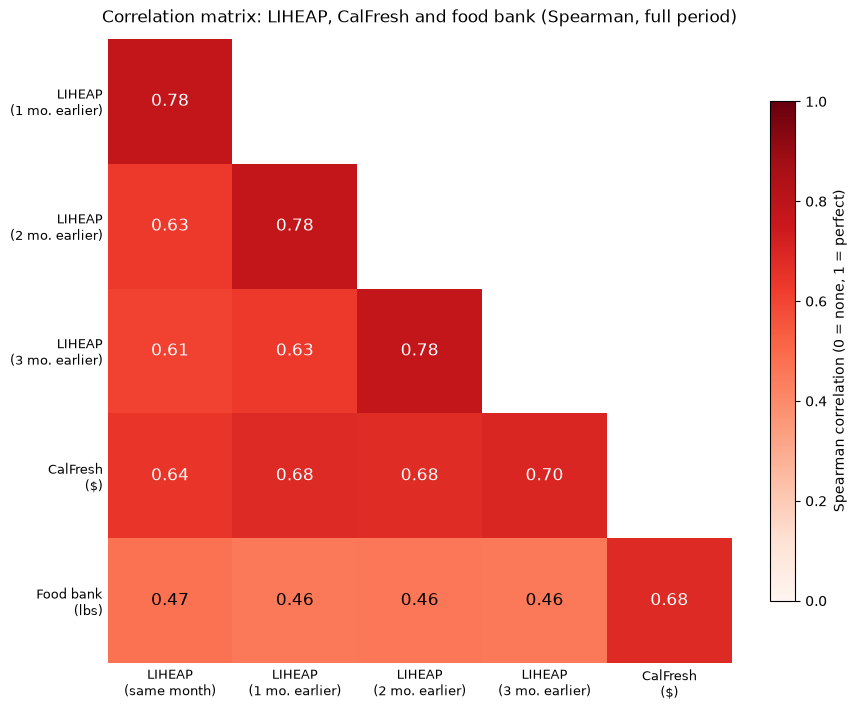

In [32]:
vars_ = ["LIHEAP_Enrollment_Count", "LIHEAP_lag1", "LIHEAP_lag2", "LIHEAP_lag3",
         "CalFresh_Total_Dollars", "FoodBank_Pounds_of_Food_Distributed"]
short = ["LIHEAP\n(same month)", "LIHEAP\n(1 mo. earlier)", "LIHEAP\n(2 mo. earlier)",
         "LIHEAP\n(3 mo. earlier)", "CalFresh\n($)", "Food bank\n(lbs)"]

d = PERIODS["Full Period"]
cm = d[vars_].corr(method="spearman", min_periods=10)
mask = np.triu(np.ones_like(cm, dtype=bool))
shown = np.where(mask, np.nan, cm.values)

fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
im = ax.imshow(shown, cmap="Reds", vmin=0, vmax=1)

for i in range(len(vars_)):
    for j in range(len(vars_)):
        if not mask[i, j]:
            v = cm.values[i, j]
            ax.text(j, i, "—" if np.isnan(v) else f"{v:.2f}", ha="center", va="center",
                    fontsize=12, color="white" if v > 0.6 else "black")

ax.set_xticks(range(len(vars_) - 1), short[:-1], fontsize=9)
ax.set_yticks(range(1, len(vars_)), short[1:], fontsize=9)
ax.set_xlim(-0.5, len(vars_) - 1.5)
ax.set_ylim(len(vars_) - 0.5, 0.5)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)
ax.set_title("Correlation matrix: LIHEAP, CalFresh and food bank (Spearman, full period)",
             fontsize=12, pad=12)

fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation (0 = none, 1 = perfect)")
plt.savefig("TimeLag_CorrelationMatrix.png", dpi=150, bbox_inches="tight")
plt.show()